In [128]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [129]:
tumor = "t57"
tumor_variants = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep = "\t")

In [130]:
A_df = pd.read_csv(f"../data/{tumor}/{tumor}_population_assignments_A_WGS_bins.txt", sep="\t")

In [131]:
normal_info = A_df[["population", "normal_population"]].drop_duplicates()
normal_A = normal_info[normal_info["normal_population"] == True]["population"].values[0]

In [132]:
A_dict = {}
for cluster in A_df['population'].unique():
    print(cluster)
    cells_in_cluster = A_df[A_df['population'] == cluster]['cell'].tolist()
    A_dict[cluster] = {
        'cells': cells_in_cluster
    }

A111
A112
A1211
A1212
A1221
A1222
A2


In [133]:
tumor_variants = tumor_variants[tumor_variants["alt_count"]>0]

In [134]:
len(tumor_variants)

18593

In [135]:
tumor_variants["chrom"].unique()

array(['chr10', 'chr11', 'chr1', 'chr12', 'chr21', 'chr13', 'chr14',
       'chr15', 'chr16', 'chr17', 'chr18', 'chr19', 'chr2', 'chr20',
       'chr4', 'chr7', 'chr22', 'chr3', 'chr5', 'chr6', 'chr8', 'chr9',
       'chrX', 'chrY'], dtype=object)

In [136]:
chrom_set = ["chr"+str(i) for i in range(1,23)] + ["chrX"]

In [137]:
pop_var_dict = {}
tot_var_dict = {}
for pop in A_dict.keys():
    pop_var_dict[pop] = {}
    tot_var_dict[pop] = 0
for ch in chrom_set:
    ch_var = tumor_variants[tumor_variants['chrom'] == ch]
    for pop in A_dict.keys():
        pop_cells = A_dict[pop]['cells']
        pop_ch_var = ch_var[ch_var['cell_id'].isin(pop_cells)]
        cells_with_var = pop_ch_var['cell_id'].unique()
        pop_var = pop_ch_var["pos"].unique()
        pop_var_dict[pop][ch] = pop_var
        tot_var_dict[pop] += len(pop_var)
    #print(pop,len(cells_with_var), len(cells_with_var)/len(pop_cells))

In [138]:
# variants per cell in each cluster
for pop in tot_var_dict:
    print(pop, tot_var_dict[pop]/len(A_dict[pop]['cells']))

A111 8.232142857142858
A112 9.347222222222221
A1211 8.476
A1212 10.622641509433961
A1221 8.407407407407407
A1222 10.132530120481928
A2 0.7884057971014493


In [139]:
#pop_var_dict

In [140]:
tumor_variants = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep = "\t")

In [141]:
tumor_variants = tumor_variants[tumor_variants["alt_count"]>0]

In [142]:
len(tumor_variants)

290

In [143]:
pop_var_dict = {}
tot_var_dict = {}
for pop in A_dict.keys():
    pop_var_dict[pop] = {}
    tot_var_dict[pop] = 0
for ch in chrom_set:
    ch_var = tumor_variants[tumor_variants['chrom'] == ch]
    for pop in A_dict.keys():
        pop_cells = A_dict[pop]['cells']
        pop_ch_var = ch_var[ch_var['cell_id'].isin(pop_cells)]
        cells_with_var = pop_ch_var['cell_id'].unique()
        pop_var = pop_ch_var["pos"].unique()
        pop_var_dict[pop][ch] = pop_var
        tot_var_dict[pop] += len(pop_var)
    #print(pop,len(cells_with_var), len(cells_with_var)/len(pop_cells))

In [144]:
# pseudo variants per cell in each cluster
for pop in tot_var_dict:
    print(pop, tot_var_dict[pop]/len(A_dict[pop]['cells']))

A111 0.0625
A112 0.06944444444444445
A1211 0.088
A1212 0.03773584905660377
A1221 0.05555555555555555
A1222 0.12048192771084337
A2 0.04173913043478261


In [145]:
# First, load the real variants
tumor_variants_real = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_variant_counts.txt", sep="\t")
#tumor_variants_real = tumor_variants_real[tumor_variants_real["alt_count"] > 0]

# Then load pseudo variants
tumor_variants_pseudo = pd.read_csv(f"../data/{tumor}/{tumor}.tumor_spec_pseudo_variants.txt", sep="\t")
#tumor_variants_pseudo = tumor_variants_pseudo[tumor_variants_pseudo["alt_count"] > 0]


In [146]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,205327,TCTTGATTGGCCCGACA,0,0,0,1,1,0,1
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
3,chr10,205327,TATTTGTAAGCTGAATC,0,0,0,1,1,0,1
4,chr10,205327,GGAACATTGGCCACACA,0,0,0,1,1,0,1


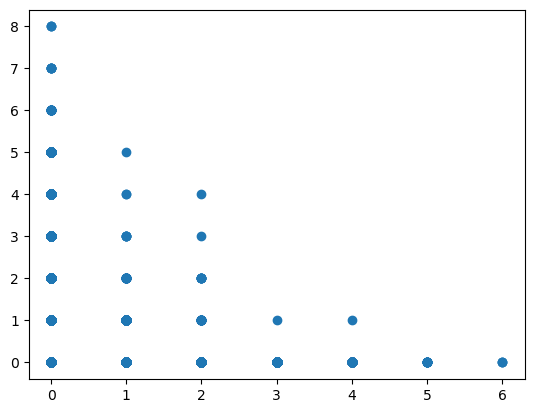

In [147]:
plt.plot(tumor_variants_real['alt_count'], tumor_variants_real['ref_count'], 'o')

In [148]:
# Initialize lists to store data
pop_names = []
opportunities_for_variants = []
opportunities_for_pseudo = []
num_variant_positions = []
num_cells_with_variants = []
variants_per_cell = []
num_pseudo_positions = []
num_cells_with_pseudo = []
pseudo_per_cell = []
Num_cells = []
# For each population, compute all metrics
for pop in A_dict.keys():
    if pop == normal_A:
        pop_names.append(pop+" (normal)")
    else:
        pop_names.append(pop)
    pop_cells = A_dict[pop]['cells']
    num_cells = len(pop_cells)
    Num_cells.append(num_cells)
    
    # Real variants
    pop_real_variants = tumor_variants_real[tumor_variants_real['cell_id'].isin(pop_cells)]
    opportunities_for_variants.append(len(pop_real_variants))
    pop_real_variants = pop_real_variants[pop_real_variants["alt_count"] > 0]
    num_variant_positions.append(len(pop_real_variants))
    num_cells_with_variants.append(len(pop_real_variants['cell_id'].unique()))
    variants_per_cell.append(len(pop_real_variants) / num_cells)
    
    # Pseudo variants
    pop_pseudo_variants = tumor_variants_pseudo[tumor_variants_pseudo['cell_id'].isin(pop_cells)]
    opportunities_for_pseudo.append(len(pop_pseudo_variants))
    pop_pseudo_variants = pop_pseudo_variants[pop_pseudo_variants["alt_count"] > 0]
    num_pseudo_positions.append(len(pop_pseudo_variants))
    num_cells_with_pseudo.append(len(pop_pseudo_variants['cell_id'].unique()))
    pseudo_per_cell.append(len(pop_pseudo_variants) / num_cells)


In [149]:
# Create the summary table
variant_summary = pd.DataFrame({
    'Population': pop_names,
    'Num_Cells': Num_cells,
    'opportunities_for_variants': opportunities_for_variants,
    'variant_observed': num_variant_positions,
    'Cells_With_Variants': num_cells_with_variants,
    'opportunities_for_pseudo': opportunities_for_pseudo,
    'pseudo_variant_observed': num_pseudo_positions,
    'Cells_With_Pseudo_variants': num_cells_with_pseudo
})

In [150]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants
0,A111,224,12476,2607,223,12626,18,16
1,A112,144,7887,1706,143,7985,12,12
2,A1211,250,15006,3150,249,15208,30,30
3,A1212,53,3106,612,52,3179,2,2
4,A1221,54,3319,496,54,3353,3,3
5,A1222,83,4802,955,83,4809,10,10
6,A2 (normal),1725,79201,3628,1356,79357,152,143


In [151]:
variant_summary["variant_frequency"] = variant_summary["variant_observed"]/variant_summary["opportunities_for_variants"]
variant_summary["pseudo_frequency"] = variant_summary["pseudo_variant_observed"]/variant_summary["opportunities_for_pseudo"]
variant_summary["variant_per_cell"] = variant_summary["variant_observed"]/variant_summary["Num_Cells"]
variant_summary["pseudo_per_cell"] = variant_summary["pseudo_variant_observed"]/variant_summary["Num_Cells"]


In [152]:
variant_summary

,Population,Num_Cells,opportunities_for_variants,variant_observed,Cells_With_Variants,opportunities_for_pseudo,pseudo_variant_observed,Cells_With_Pseudo_variants,variant_frequency,pseudo_frequency,variant_per_cell,pseudo_per_cell
0,A111,224,12476,2607,223,12626,18,16,0.208961,0.001426,11.638393,0.080357
1,A112,144,7887,1706,143,7985,12,12,0.216305,0.001503,11.847222,0.083333
2,A1211,250,15006,3150,249,15208,30,30,0.209916,0.001973,12.600000,0.120000
3,A1212,53,3106,612,52,3179,2,2,0.197038,0.000629,11.547170,0.037736
4,A1221,54,3319,496,54,3353,3,3,0.149443,0.000895,9.185185,0.055556
5,A1222,83,4802,955,83,4809,10,10,0.198875,0.002079,11.506024,0.120482
6,A2 (normal),1725,79201,3628,1356,79357,152,143,0.045808,0.001915,2.103188,0.088116


In [153]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,205327,TCTTGATTGGCCCGACA,0,0,0,1,1,0,1
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
3,chr10,205327,TATTTGTAAGCTGAATC,0,0,0,1,1,0,1
4,chr10,205327,GGAACATTGGCCACACA,0,0,0,1,1,0,1


In [154]:
tumor_info = tumor_variants_real[~tumor_variants_real["cell_id"].isin(A_dict[normal_A]["cells"])]

In [155]:
pos_groups = tumor_info.groupby(["chrom", "pos"])

In [156]:
tumor_info

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
5,chr10,205327,GACCCTTGAGGTACAAT,0,0,0,1,1,0,1
6,chr10,205327,GGTTTAGGCTATGCATA,0,0,0,2,2,0,2
9,chr10,205327,AACGGGGTTACTGCAGT,0,1,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...
160896,chrY,59025486,GGTGCAGCCTCTTCAAG,0,0,1,0,1,0,1
160897,chrY,59025486,GGCTGTTCTTCAGAACT,0,0,1,0,1,0,1
160899,chrY,59025486,GACACGGAACAAGTTAG,0,0,1,0,1,0,1
160900,chrY,59025486,AAAGGCTAATTTTCTCG,0,0,1,0,1,0,1


In [157]:
# List all unique (chrom, pos) combinations
unique_positions = tumor_info[["chrom", "pos"]].drop_duplicates().values.tolist()

In [158]:
p = unique_positions[0]
df = pos_groups.get_group((p[0], p[1]))


In [159]:
row_list = []
for p in unique_positions:
    df = pos_groups.get_group((p[0], p[1]))
    r_count = df["ref_count"].sum()
    a_count = df["alt_count"].sum()
    tot = df["total_count"].sum()
    row_list.append({
        "chrom": p[0],
        "pos": p[1],
        "ref_count": r_count,
        "alt_count": a_count,
        "total_count": tot,
        "variant_frequency": a_count / tot
    })

tumor_variant_summary = pd.DataFrame(row_list)

In [160]:
tumor_variant_summary.head()

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
0,chr10,205327,4,2,6,0.333333
1,chr10,205975,1,1,2,0.500000
2,chr10,210169,20,3,24,0.125000
3,chr10,449603,1,0,1,0.000000
4,chr10,769746,1,0,1,0.000000


In [161]:
high = tumor_variant_summary[tumor_variant_summary["total_count"] > 20]

In [162]:
high[high["chrom"]=="chr4"].sort_values(by="variant_frequency", ascending=False).head()

,chrom,pos,ref_count,alt_count,total_count,variant_frequency
7406,chr4,165918027,17,36,53,0.679245
7480,chr4,190530226,10,17,27,0.629630
7488,chr4,190880011,5,15,24,0.625000
7123,chr4,88259894,13,18,31,0.580645
7084,chr4,76052318,13,12,25,0.480000


<Axes: >

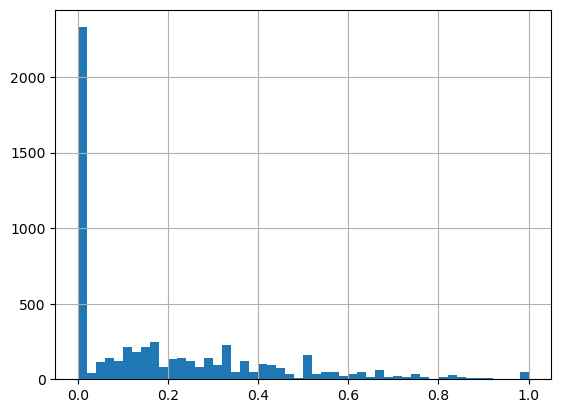

In [163]:
tumor_variant_summary[tumor_variant_summary["total_count"] > 5]["variant_frequency"].hist(bins=50) 

<Axes: >

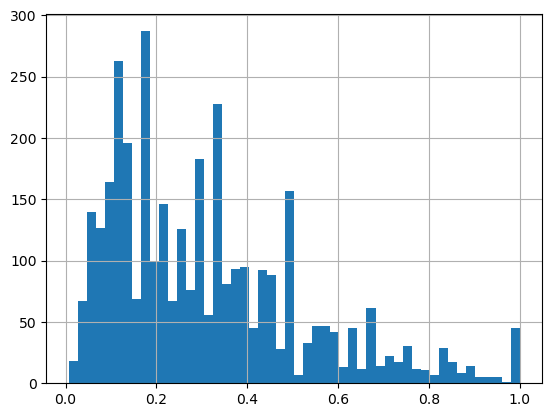

In [164]:
tumor_variant_summary[(tumor_variant_summary["variant_frequency"]!=0) & (tumor_variant_summary["total_count"] > 5)]["variant_frequency"].hist(bins=50)

In [165]:
well_covered_non_zero_variants = tumor_variant_summary[(tumor_variant_summary["total_count"] > 20) & (tumor_variant_summary["variant_frequency"] > 0)]

In [166]:
tumor_clones = [ t for t in A_dict.keys() if t != normal_A ]

In [167]:
t = tumor_clones[0]

In [168]:
tumor_variants_real.head()

,chrom,pos,cell_id,A_count,T_count,C_count,G_count,ref_count,alt_count,total_count
0,chr10,205327,TCTTGATTGGCCCGACA,0,0,0,1,1,0,1
1,chr10,205327,ATGCCAAGTCACGGATT,0,0,0,1,1,0,1
2,chr10,205327,CAAGGAGTGCGTCGTGA,0,1,0,0,0,1,1
3,chr10,205327,TATTTGTAAGCTGAATC,0,0,0,1,1,0,1
4,chr10,205327,GGAACATTGGCCACACA,0,0,0,1,1,0,1


In [169]:
unique_positions = well_covered_non_zero_variants[["chrom", "pos"]].drop_duplicates().values.tolist()

/var/folders/p3/qk0s0_l96v7679y441dyvbx80000gn/T/ipykernel_10868/4130353737.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(vaf_list, labels=tumor_clones)


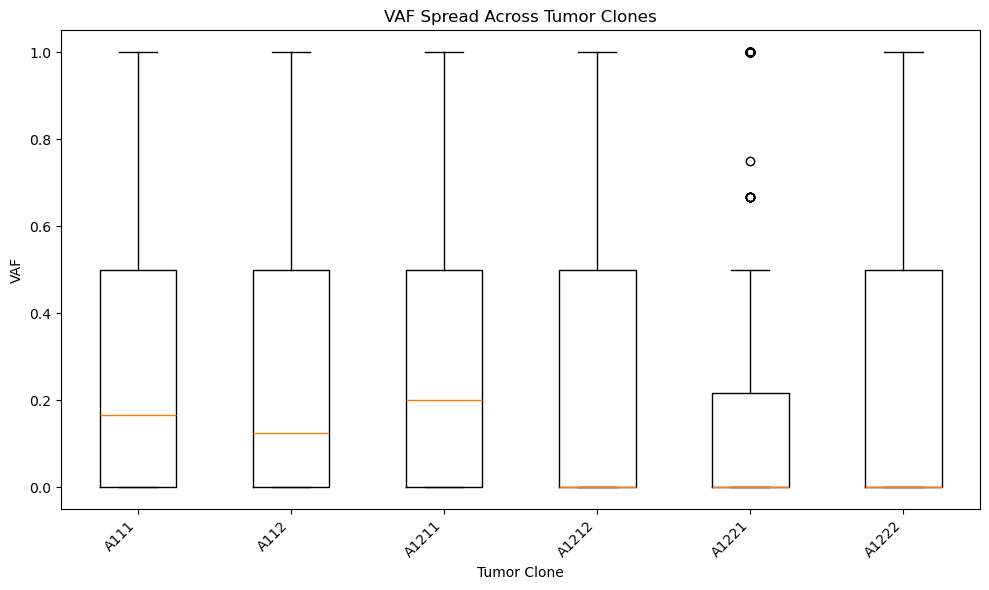

In [170]:
vaf_list = []

for t in tumor_clones:
    # Get variant data for this tumor clone

    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    #unique_positions = tumor_clone_info[["chrom", "pos"]].drop_duplicates().values.tolist()
    
    vaf_spread = []
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    
    vaf_list.append(vaf_spread)  # This should be OUTSIDE the position loop

# Now plot
plt.figure(figsize=(10, 6))
plt.boxplot(vaf_list, labels=tumor_clones)
plt.ylabel("VAF")
plt.xlabel("Tumor Clone")
plt.title("VAF Spread Across Tumor Clones")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

A111 667


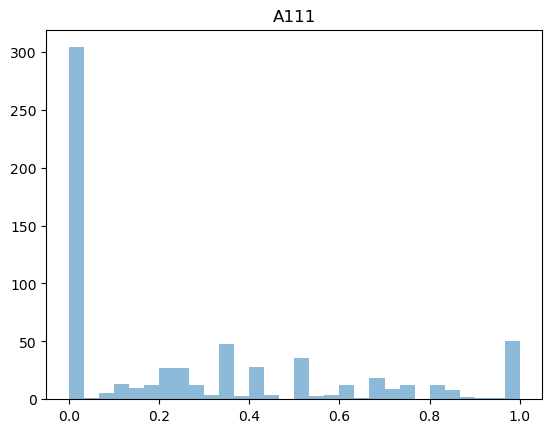

A112 610


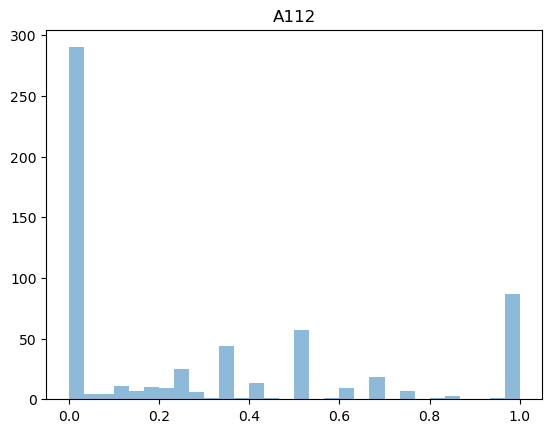

A1211 680


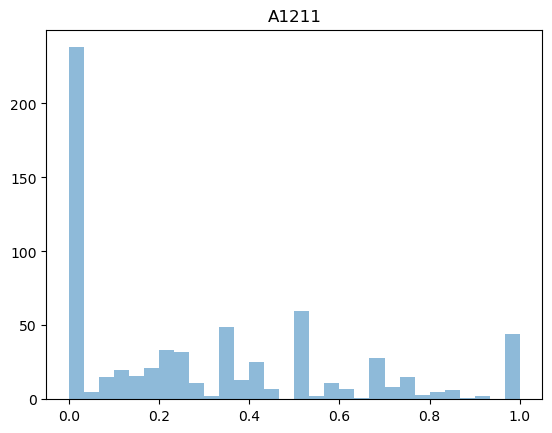

A1212 415


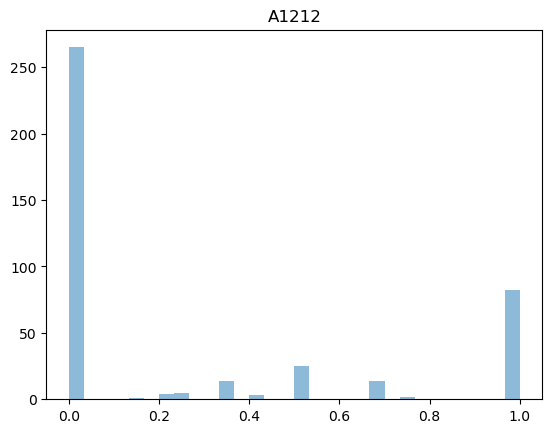

A1221 426


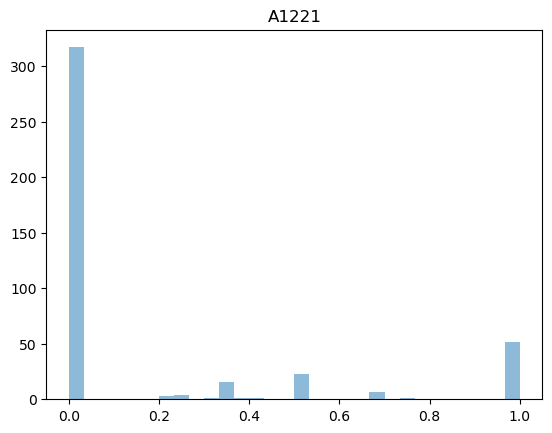

A1222 508


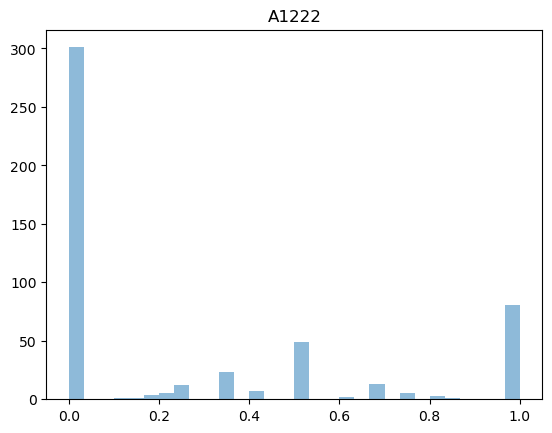

In [171]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()
# plt.xlabel("VAF")
# plt.ylabel("Frequency")
# plt.title("VAF Distribution Across Tumor Clones")
# plt.legend()
# plt.show()

In [178]:
well_covered = tumor_variant_summary[(tumor_variant_summary["alt_count"] > 3) & (tumor_variant_summary["total_count"] > 10) ]

<Axes: >

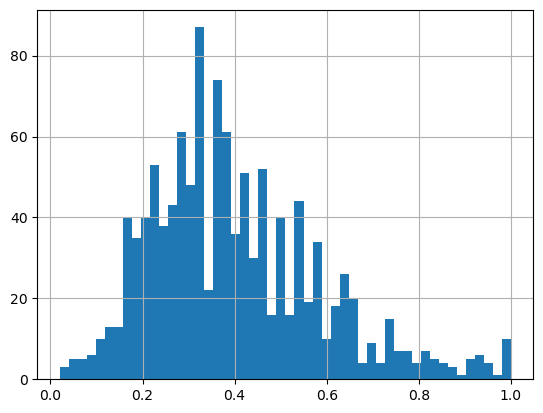

In [179]:
well_covered["variant_frequency"].hist(bins=50)

In [180]:
unique_positions = well_covered[["chrom", "pos"]].drop_duplicates().values.tolist()
vaf_list = []
row_list = []
for t in A_dict.keys():
    # Get variant data for this tumor clone
    tumor_clone_info = tumor_variants_real[tumor_variants_real["cell_id"].isin(A_dict[t]["cells"])]
    vaf_spread = []
    var_count = 0
    tot_count = 0
    for p in unique_positions:
        try:
            # Get all observations of this variant position across cells in this clone
            df = tumor_clone_info[(tumor_clone_info["chrom"] == p[0]) & (tumor_clone_info["pos"] == p[1])]
            r_count = df["ref_count"].sum()
            a_count = df["alt_count"].sum()
            tot = df["total_count"].sum()
            var_count += a_count
            tot_count += tot
            
            if tot > 0:  # Avoid division by zero
                vaf = a_count / tot
                vaf_spread.append(vaf)
        except:
            continue
    row_list.append({"tumor_clone": t, "var_count": var_count, "tot_count": tot_count, "vaf": var_count/tot_count})
    
    vaf_list.append(vaf_spread)  
    
    

A111 1035


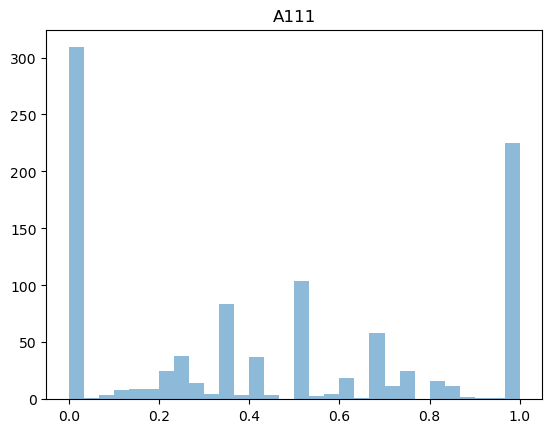

A112 875


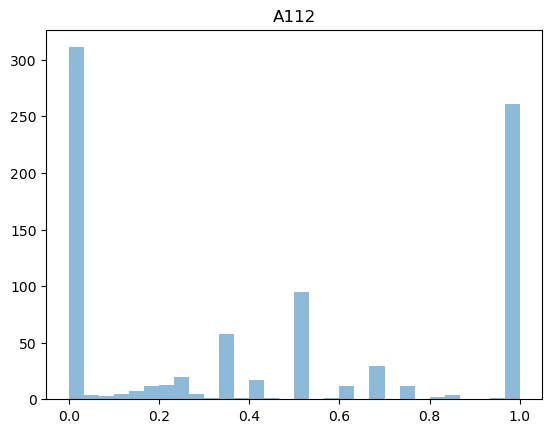

A1211 1082


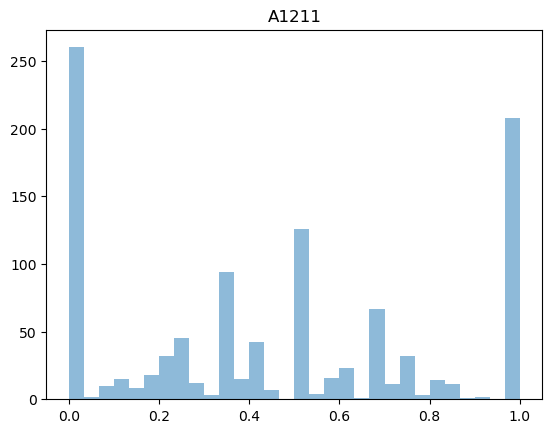

A1212 565


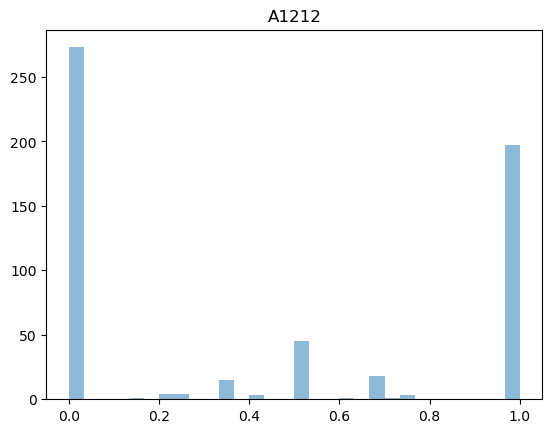

A1221 546


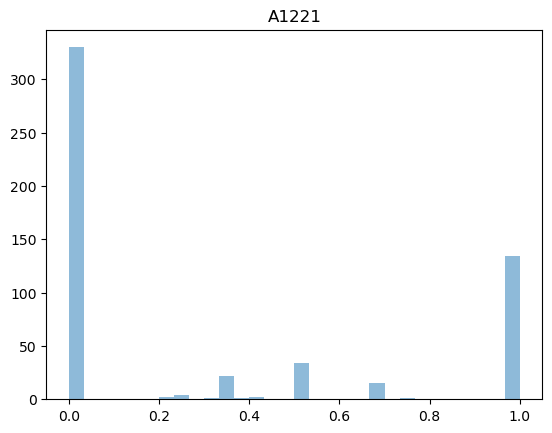

A1222 720


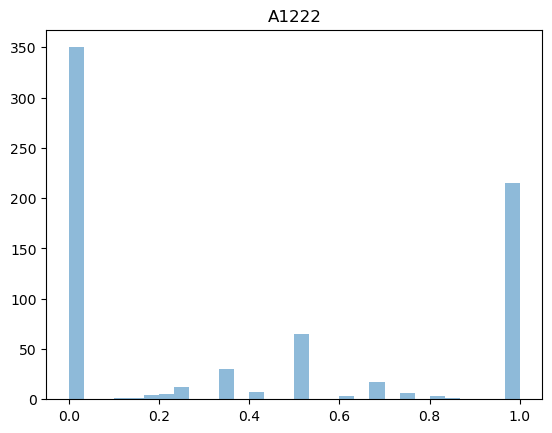

In [181]:
for l, v in zip(tumor_clones, vaf_list):
    print(l, len(v))
    plt.hist(v, bins=30, alpha=0.5, label=l)
    plt.title(l)
    plt.show()

In [182]:
pd.DataFrame(row_list)

,tumor_clone,var_count,tot_count,vaf
0,A111,1662,4189,0.396753
1,A112,1067,2675,0.398879
2,A1211,2060,5042,0.408568
3,A1212,409,1007,0.406157
4,A1221,305,1041,0.292988
5,A1222,570,1537,0.370852
6,A2,2056,22119,0.092952


In [183]:
len(unique_positions)

1165